# Comparación de modelos, selección y conclusiones

### Entorno y persistencia de resultados

En la celda siguiente fijé tres cosas que condicionan la reproducibilidad del experimento.

**Semilla fija.** Usé `RANDOM_STATE = 42` en la partición train/test y en el ajuste de todos los
modelos. Sin ella, cada ejecución produciría particiones distintas y las métricas no serían
comparables entre corridas ni verificables por un tercero.

**Persistencia en Google Drive.** Escribí los resultados en `MyDrive/bank_marketing` y no en el
disco temporal de Colab, que se borra al cerrar la sesión. El notebook 03 deja las particiones
preparadas y los notebooks 04 y 05 las consumen tal cual, de modo que todos operan sobre exactamente
los mismos datos. Si el montaje no se completa, la celda interrumpe la ejecución en lugar de escribir
en una ubicación volátil. Fuera de Colab no hace falta Drive, y los resultados se escriben en la
carpeta del repositorio (los gráficos en `splits/`).

**Registro de las figuras.** La función `guardar` escribe cada gráfico en `splits/` como PNG a 200
dpi. La invoco antes de `plt.show()`, porque mostrar la figura vacía el buffer de matplotlib y el
archivo saldría en blanco.

In [1]:
import os, io, time, json, zipfile, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

EN_DRIVE = False
try:
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.isdir("/content/drive/MyDrive"):
        raise RuntimeError(
            "Drive no quedó montado. Vuelve a ejecutar esta celda y autoriza el acceso "
            "en la ventana emergente."
        )
    RUTA = "/content/drive/MyDrive/bank_marketing"
    EN_DRIVE = True
except ImportError:
    RUTA = os.path.abspath(".." if os.path.basename(os.getcwd()) == "notebooks" else ".")

CARPETA_SPLITS = os.path.join(RUTA, "splits")
os.makedirs(CARPETA_SPLITS, exist_ok=True)

def guardar(nombre):
    destino = os.path.join(CARPETA_SPLITS, nombre + ".png")
    plt.savefig(destino, dpi=200, bbox_inches="tight", facecolor="white")
    print("Gráfico guardado:", destino)

print("Guardando en Google Drive" if EN_DRIVE else "Google Drive no disponible: guardando localmente")
print("Ruta de trabajo:", RUTA)

Google Drive no disponible: guardando localmente
Ruta de trabajo: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing


## Carga de resultados

Leí `resultados_modelos.json` (una entrada por modelo), `puntajes_test.npz` (el puntaje que cada modelo
asignó a cada cliente de prueba, necesario para las curvas ROC) y `entorno.json` (la máquina donde se
midieron los tiempos). En este notebook no entrené nada, de modo que la tabla, las figuras y la selección
salen de los mismos archivos y no pueden contradecirse entre sí. Si falta alguno de los archivos, el
notebook 04 no se ejecutó completo.

In [2]:
from sklearn.metrics import roc_curve, roc_auc_score, ConfusionMatrixDisplay

with open(os.path.join(RUTA, "resultados_modelos.json"), encoding="utf-8") as f:
    resultados = json.load(f)
puntajes = np.load(os.path.join(RUTA, "puntajes_test.npz"))
with open(os.path.join(RUTA, "entorno.json"), encoding="utf-8") as f:
    entorno = json.load(f)
y_test = puntajes["y_test"]

nombres = {"SVM": "SVM", "Arbol": "Árbol de decisión", "RandomForest": "Random Forest", "XGBoost": "XGBoost"}
colores = {"SVM": "#2a6f97", "Arbol": "#c8553d", "RandomForest": "#3a7d44", "XGBoost": "#7b2d8e"}
modelos = list(nombres)
print("Modelos cargados:", list(resultados))
print("Clientes de prueba:", len(y_test), "| contratadores:", int(y_test.sum()))
print("Entorno de medición:", entorno["procesador"], "|", entorno["nucleos_logicos"], "núcleos lógicos |",
      entorno["memoria_gb"], "GB de memoria | scikit-learn", entorno["scikit_learn"], "| xgboost", entorno["xgboost"])

Modelos cargados: ['Baseline', 'SVM', 'Arbol', 'RandomForest', 'XGBoost']
Clientes de prueba: 9043 | contratadores: 1058
Entorno de medición: Intel64 Family 6 Model 154 Stepping 3, GenuineIntel | 16 núcleos lógicos | 31.7 GB de memoria | scikit-learn 1.8.0 | xgboost 3.4.1


## Tabla comparativa

Armé la tabla con las cinco métricas de rendimiento sobre el conjunto de prueba y los dos tiempos
(medianas de varias repeticiones). Mostré la línea base aparte, como piso de referencia, y guardé la tabla
como CSV para el informe, con el rango de los tiempos incluido.

In [3]:
def fila(clave):
    r = resultados[clave]
    return {"accuracy": r["test"]["accuracy"], "precision": r["test"]["precision"], "recall": r["test"]["recall"],
            "f1": r["test"]["f1"], "roc_auc": r["test"]["roc_auc"],
            "t_entrenamiento_s": r["tiempo_entrenamiento_s"], "t_prediccion_s": r["tiempo_prediccion_s"],
            "t_entrenamiento_min_s": r.get("rango_entrenamiento_s", [np.nan, np.nan])[0],
            "t_entrenamiento_max_s": r.get("rango_entrenamiento_s", [np.nan, np.nan])[1],
            "t_prediccion_min_s": r["rango_prediccion_s"][0], "t_prediccion_max_s": r["rango_prediccion_s"][1]}

tabla = pd.DataFrame({nombres[k]: fila(k) for k in modelos}).T
tabla.index.name = "modelo"
tabla.round(4).to_csv(os.path.join(RUTA, "tabla_comparativa.csv"))
print(tabla[["accuracy", "precision", "recall", "f1", "roc_auc", "t_entrenamiento_s", "t_prediccion_s"]].round(
    {"accuracy": 4, "precision": 4, "recall": 4, "f1": 4, "roc_auc": 4, "t_entrenamiento_s": 2, "t_prediccion_s": 3}).to_string())
print("\nRango de los tiempos (mínimo y máximo de las repeticiones, en segundos):")
print(tabla[["t_entrenamiento_min_s", "t_entrenamiento_max_s", "t_prediccion_min_s", "t_prediccion_max_s"]].round(3).to_string())
print("\nLínea base (siempre 'no'):")
print(pd.Series(fila("Baseline")).round(4).to_string())

                   accuracy  precision  recall      f1  roc_auc  t_entrenamiento_s  t_prediccion_s
modelo                                                                                            
SVM                  0.8704     0.4531  0.5208  0.4846   0.7907              96.64          44.382
Árbol de decisión    0.8796     0.4852  0.4792  0.4822   0.7592               0.68           0.070
Random Forest        0.8702     0.4545  0.5473  0.4966   0.8083              34.67           0.813
XGBoost              0.8728     0.4634  0.5510  0.5035   0.8083               4.87           0.114

Rango de los tiempos (mínimo y máximo de las repeticiones, en segundos):
                   t_entrenamiento_min_s  t_entrenamiento_max_s  t_prediccion_min_s  t_prediccion_max_s
modelo                                                                                                 
SVM                               94.815                300.368              44.329              44.595
Árbol de decisión   

**Lectura.** La tabla resume el experimento. En rendimiento, XGBoost queda primero en F1 (0,504) y empata
con el Random Forest en AUC (0,808). Les siguen el Random Forest (F1 0,497), el SVM (0,485 y AUC 0,791) y
el árbol (0,482 y AUC 0,759). Las accuracy quedan entre 0,870 y 0,880, cerca de la línea base, porque con
la clase positiva tan pequeña la accuracy casi no distingue a los modelos. En costo, el árbol entrena en
0,7 segundos, XGBoost en unos 5, el Random Forest en unos 35 y el SVM en más de 90. En predicción, el SVM
tarda unos 44 segundos para 9.043 clientes, cientos de veces lo que tarda XGBoost. Los tiempos absolutos
cambian de una ejecución a otra (dentro de esta ejecución el SVM tardó entre 95 y 300 segundos en
entrenar), pero el orden entre los modelos se mantuvo en todas las corridas, y por eso las conclusiones
se apoyan en las razones entre tiempos y no en los segundos exactos.

## Efecto del ajuste del umbral

Comparé el F1 de cada modelo en prueba con el umbral por defecto y con el umbral elegido sin mirar la
prueba. El ROC-AUC no cambia, porque el umbral no modifica el orden de los clientes, solo dónde se corta
la lista.

In [4]:
efecto_umbral = pd.DataFrame({nombres[k]: {
    "umbral por defecto": resultados[k]["umbral_defecto"], "umbral ajustado": resultados[k]["umbral"],
    "F1 con umbral por defecto": resultados[k]["test_umbral_defecto"]["f1"], "F1 con umbral ajustado": resultados[k]["test"]["f1"],
    "precisión ajustada": resultados[k]["test"]["precision"], "recall ajustado": resultados[k]["test"]["recall"]} for k in modelos}).T
efecto_umbral["ganancia de F1"] = efecto_umbral["F1 con umbral ajustado"] - efecto_umbral["F1 con umbral por defecto"]
print(efecto_umbral.round(4).to_string())

                   umbral por defecto  umbral ajustado  F1 con umbral por defecto  F1 con umbral ajustado  precisión ajustada  recall ajustado  ganancia de F1
SVM                               0.0           0.4637                     0.4580                  0.4846              0.4531           0.5208          0.0266
Árbol de decisión                 0.5           0.6702                     0.4723                  0.4822              0.4852           0.4792          0.0098
Random Forest                     0.5           0.4800                     0.5004                  0.4966              0.4545           0.5473         -0.0039
XGBoost                           0.5           0.6273                     0.4609                  0.5035              0.4634           0.5510          0.0426


**Lectura.** El ajuste del umbral fue la mejora más grande en XGBoost (de 0,461 a 0,504) y en el SVM (de
0,458 a 0,485), y una ganancia menor en el árbol (de 0,472 a 0,482). En el Random Forest el umbral elegido
por OOB casi coincide con 0,5 y el F1 bajó 0,004, una diferencia que está dentro del ruido. Que no todos
mejoren es esperable, porque el umbral se eligió sin mirar la prueba. Lo importante es que la
comparación entre modelos se hace con cada uno en su mejor punto de operación, y no con un umbral que
favorece a unos y perjudica a otros.

## Rendimiento frente a costo

Puse en un mismo plano lo que cada modelo rinde (F1 de la clase positiva) y lo que cuesta (tiempo de
entrenamiento y de predicción en escala logarítmica, porque los modelos se separan por órdenes de
magnitud). El mejor lugar del gráfico es arriba a la izquierda, donde el modelo rinde más y cuesta menos.

Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\05_rendimiento_vs_costo.png


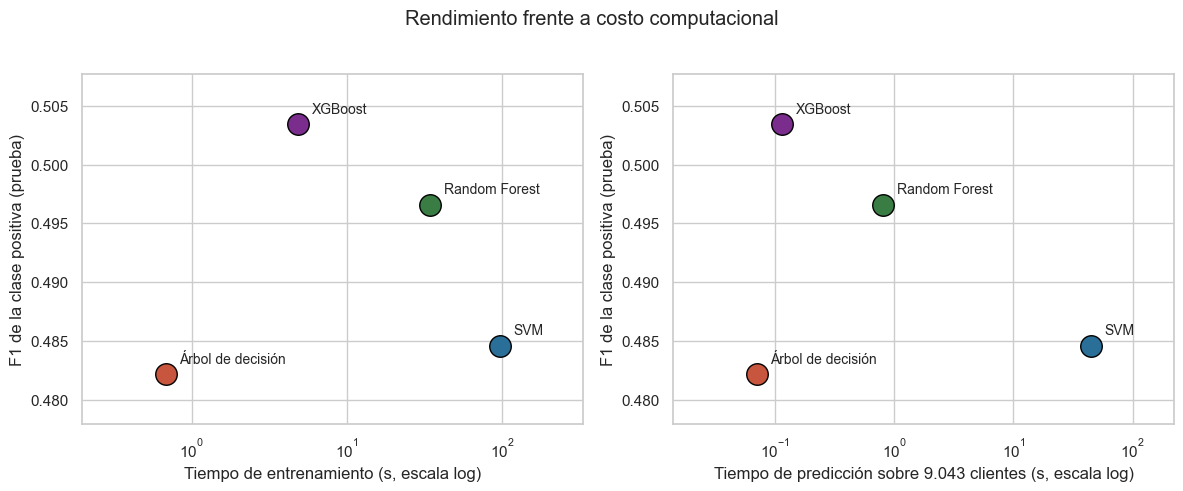

In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.8))
for eje, columna, titulo in [(ejes[0], "t_entrenamiento_s", "Tiempo de entrenamiento (s, escala log)"),
                             (ejes[1], "t_prediccion_s", "Tiempo de predicción sobre 9.043 clientes (s, escala log)")]:
    for k in modelos:
        eje.scatter(tabla.loc[nombres[k], columna], tabla.loc[nombres[k], "f1"], s=240, color=colores[k],
                    edgecolor="black", zorder=3)
        eje.annotate(nombres[k], (tabla.loc[nombres[k], columna], tabla.loc[nombres[k], "f1"]),
                     textcoords="offset points", xytext=(10, 8), fontsize=10)
    eje.set_xscale("log")
    eje.set_xlabel(titulo)
    eje.set_ylabel("F1 de la clase positiva (prueba)")
    eje.margins(x=0.25, y=0.2)
plt.suptitle("Rendimiento frente a costo computacional", y=1.02)
plt.tight_layout()
guardar("05_rendimiento_vs_costo")
plt.show()

**Lectura.** La esquina deseable es arriba a la izquierda, y ahí queda XGBoost en las dos figuras, con el
mejor F1 y el segundo menor costo. El árbol es el más barato pero queda abajo, el Random Forest rinde casi
igual que XGBoost pero cuesta unas siete veces más, y el SVM queda abajo a la derecha, es decir que es el
más caro y no tiene la ventaja de rendimiento que podría justificar ese costo. El eje vertical abarca
pocos puntos de F1, así que las diferencias de altura se ven más grandes de lo que son.

## Curvas ROC

Grafiqué la curva ROC de cada modelo, que muestra cómo se comporta en todos los umbrales posibles y no
solo en el de 0,5. El área bajo la curva (AUC) resume qué tan bien ordena a los clientes de más a menos
probables, que es justamente lo que necesita una campaña que prioriza llamadas.

Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\05_curvas_roc.png


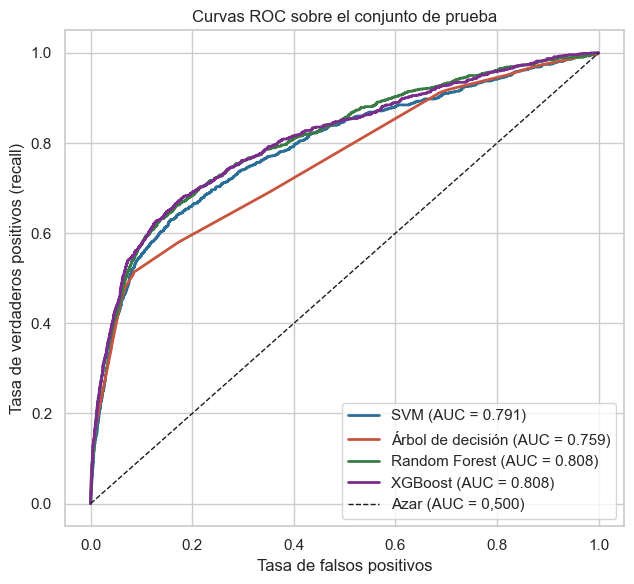

In [6]:
plt.figure(figsize=(6.5, 6))
for k in modelos:
    fpr, tpr, _ = roc_curve(y_test, puntajes[k])
    plt.plot(fpr, tpr, color=colores[k], lw=2, label=f"{nombres[k]} (AUC = {resultados[k]['test']['roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Azar (AUC = 0,500)")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos (recall)")
plt.title("Curvas ROC sobre el conjunto de prueba")
plt.legend(loc="lower right")
plt.tight_layout()
guardar("05_curvas_roc")
plt.show()

**Lectura.** Las curvas del Random Forest y de XGBoost casi se superponen en todo el rango, con AUC de
0,808 los dos. El SVM queda un poco por debajo (0,791) y el árbol más abajo (0,759), con una curva hecha de
pocos escalones porque solo tiene 44 hojas. Los cuatro están muy por encima del azar, pero ninguno separa
las clases con claridad, lo que coincide con la debilidad de las correlaciones vista en el notebook 02.

## Estabilidad: ¿las diferencias son reales?

Con 9.043 clientes de prueba y solo unos 1.058 contratadores, una diferencia de un par de puntos en F1
puede ser ruido. Grafiqué el intervalo de confianza del 95 % de F1 y de AUC obtenido por bootstrap en el
notebook 04. Si los intervalos de dos modelos se traslapan, el conjunto de prueba no alcanza para afirmar
que uno es mejor que el otro.

Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\05_intervalos_bootstrap.png


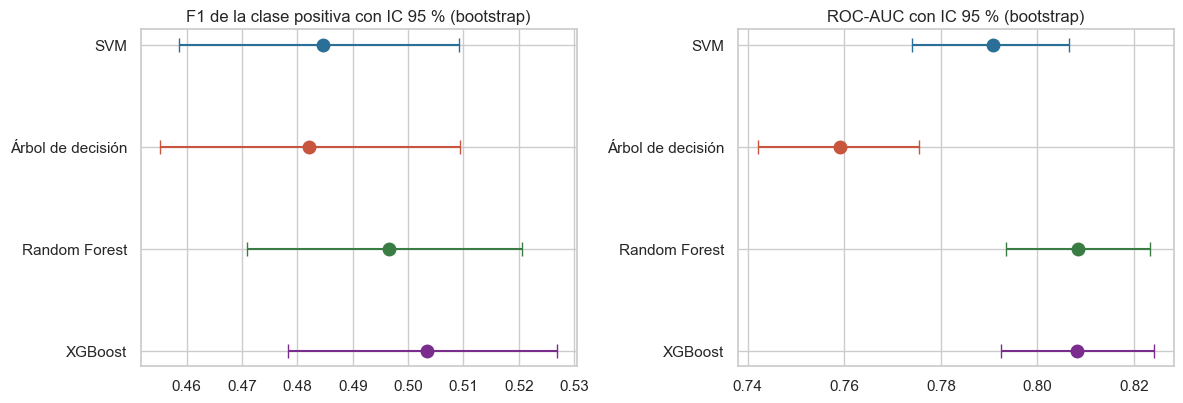

                       F1  F1 IC bajo  F1 IC alto     AUC  AUC IC bajo  AUC IC alto  desv. bootstrap F1
SVM                0.4846      0.4587      0.5091  0.7907       0.7741       0.8065              0.0130
Árbol de decisión  0.4822      0.4553      0.5093  0.7592       0.7420       0.7754              0.0132
Random Forest      0.4966      0.4710      0.5206  0.8083       0.7936       0.8232              0.0124
XGBoost            0.5035      0.4783      0.5269  0.8083       0.7925       0.8242              0.0124


In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))
for eje, metrica, clave_ic, titulo in [(ejes[0], "f1", "ic95_f1", "F1 de la clase positiva"),
                                       (ejes[1], "roc_auc", "ic95_auc", "ROC-AUC")]:
    for i, k in enumerate(modelos):
        valor = resultados[k]["test"][metrica]
        bajo, alto = resultados[k][clave_ic]
        eje.errorbar(valor, i, xerr=[[valor - bajo], [alto - valor]], fmt="o", color=colores[k], capsize=5, markersize=9)
    eje.set_yticks(range(len(modelos)))
    eje.set_yticklabels([nombres[k] for k in modelos])
    eje.invert_yaxis()
    eje.set_title(titulo + " con IC 95 % (bootstrap)")
plt.tight_layout()
guardar("05_intervalos_bootstrap")
plt.show()

intervalos = pd.DataFrame({nombres[k]: {"F1": resultados[k]["test"]["f1"], "F1 IC bajo": resultados[k]["ic95_f1"][0],
                                        "F1 IC alto": resultados[k]["ic95_f1"][1], "AUC": resultados[k]["test"]["roc_auc"],
                                        "AUC IC bajo": resultados[k]["ic95_auc"][0], "AUC IC alto": resultados[k]["ic95_auc"][1],
                                        "desv. bootstrap F1": resultados[k]["desv_f1_bootstrap"]} for k in modelos}).T
print(intervalos.round(4).to_string())

**Lectura.** En F1 los cuatro intervalos se traslapan (entre 0,478 y 0,509 comparten rango), así que con
este conjunto de prueba la ventaja de XGBoost en F1 es plausible pero no concluyente. En AUC la situación
es distinta para el árbol, cuyo intervalo (0,742 a 0,775) no toca los del Random Forest ni XGBoost (desde
0,793), de modo que el árbol ordena peor a los clientes con seguridad. Es una comparación conservadora,
porque no empareja las muestras de bootstrap entre modelos. La estabilidad por bootstrap es parecida en
todos (desviación de 0,012 a 0,013).

## Sesgo y varianza

La brecha entre el desempeño sobre entrenamiento y sobre prueba es la lectura práctica del
sesgo-varianza. Un modelo con desempeño bajo en ambos sufre sesgo (es demasiado simple para el
problema), y uno con desempeño alto en entrenamiento y bajo en prueba sufre varianza (memoriza). Medí el
entrenamiento con una muestra de 9.043 filas para que el SVM no tuviera que predecir sobre todo el
conjunto.

                   F1 entrenamiento  F1 prueba  brecha F1  AUC entrenamiento  AUC prueba  brecha AUC
modelo                                                                                              
SVM                          0.4930     0.4846     0.0084             0.7994      0.7907      0.0087
Árbol de decisión            0.4552     0.4822    -0.0270             0.7454      0.7592     -0.0137
Random Forest                0.7125     0.4966     0.2159             0.9679      0.8083      0.1596
XGBoost                      0.5157     0.5035     0.0123             0.8412      0.8083      0.0330


Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\05_sesgo_varianza.png


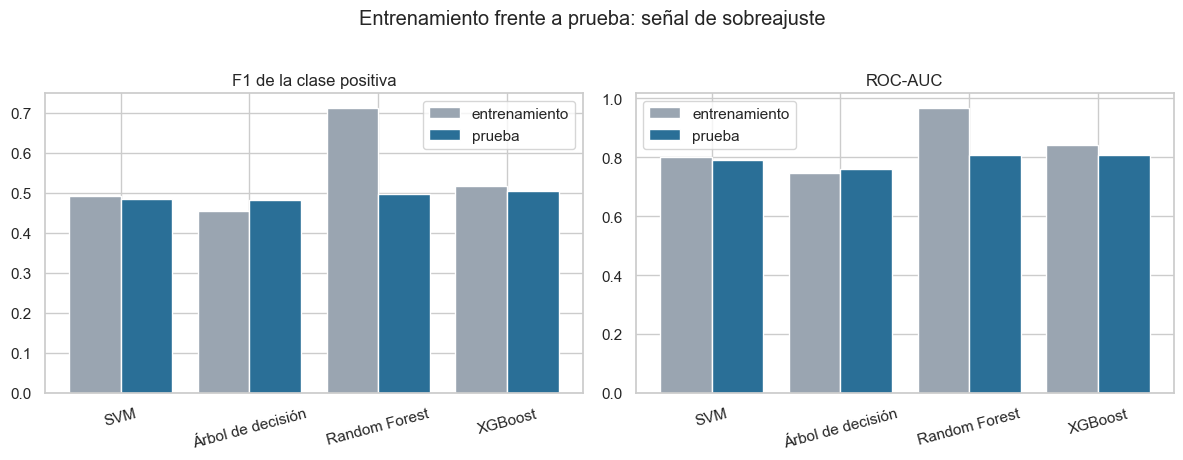

In [8]:
filas = []
for k in modelos:
    r = resultados[k]
    filas.append({"modelo": nombres[k],
                  "F1 entrenamiento": r["train_muestra"]["f1"], "F1 prueba": r["test"]["f1"],
                  "brecha F1": r["train_muestra"]["f1"] - r["test"]["f1"],
                  "AUC entrenamiento": r["train_muestra"]["roc_auc"], "AUC prueba": r["test"]["roc_auc"],
                  "brecha AUC": r["train_muestra"]["roc_auc"] - r["test"]["roc_auc"]})
sesgo_varianza = pd.DataFrame(filas).set_index("modelo")
print(sesgo_varianza.round(4).to_string())

posicion = np.arange(len(modelos))
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=False)
for eje, metrica, titulo in [(ejes[0], "F1", "F1 de la clase positiva"), (ejes[1], "AUC", "ROC-AUC")]:
    eje.bar(posicion - 0.2, sesgo_varianza[metrica + " entrenamiento"], width=0.4, label="entrenamiento", color="#9aa5b1")
    eje.bar(posicion + 0.2, sesgo_varianza[metrica + " prueba"], width=0.4, label="prueba", color="#2a6f97")
    eje.set_xticks(posicion)
    eje.set_xticklabels(sesgo_varianza.index, rotation=15)
    eje.set_title(titulo)
    eje.legend()
plt.suptitle("Entrenamiento frente a prueba: señal de sobreajuste", y=1.02)
plt.tight_layout()
guardar("05_sesgo_varianza")
plt.show()

**Lectura.** El SVM, el árbol y XGBoost tienen brechas pequeñas (0,008, -0,027 y 0,012 en F1), y en el
árbol el desempeño en prueba incluso supera al de la muestra de entrenamiento, lo que descarta el
sobreajuste. El SVM y el árbol, con desempeño modesto en ambos conjuntos, son modelos de sesgo alto, que
no logran capturar más señal de la que su estructura permite. XGBoost logra el mejor desempeño con una
brecha casi igual de pequeña, gracias al early stopping y a una tasa de aprendizaje baja. El Random Forest
tiene la mayor varianza (brecha de 0,216 en F1 y 0,160 en AUC), porque sus árboles profundos memorizan casi
todo el entrenamiento y el promedio solo corrige parte de ese efecto.

## Utilidad para la campaña: captura en el 20 % superior

La métrica que más se parece a la decisión del banco es la captura en el 20 % superior. Si solo se puede
llamar al 20 % de la lista, mide qué fracción de los contratadores queda dentro. Un orden al azar captura
el 20 %. La calculé sobre el puntaje de cada modelo en el conjunto de prueba.

In [9]:
captura = pd.Series({nombres[k]: resultados[k]["captura_top20"] for k in modelos})
print((100 * captura).round(1).astype(str) + " %")
print("\nAzar: 20.0 %")

SVM                  61.2 %
Árbol de decisión    56.1 %
Random Forest        63.2 %
XGBoost              63.5 %
dtype: str

Azar: 20.0 %


**Lectura.** Esta es la cifra más cercana a la decisión del banco. Si solo puede llamar al 20 % de la
lista, XGBoost captura el 63,5 % de los contratadores, el Random Forest el 63,2 %, el SVM el 61,2 % y el
árbol el 56,1 %. Es más de tres veces lo que lograría una lista al azar (20 %).

## Criterios de selección

No seleccioné el modelo con una sola métrica. Ordené los cuatro modelos en los criterios que importan
para esta decisión y los leí juntos.

| Criterio | Cómo se mide |
|---|---|
| Rendimiento | F1 de la clase positiva y ROC-AUC en prueba |
| Estabilidad | Desviación estándar de F1 por bootstrap y brecha entre entrenamiento y prueba |
| Costo | Tiempo de entrenamiento y de predicción |
| Interpretabilidad | Criterio cualitativo sobre cuánto se puede explicar a un gerente de campaña |

El orden 1 es el mejor en cada criterio. La interpretabilidad no la calculé, la asigné a partir de cómo
funciona cada familia (un árbol se lee como reglas; un bosque o un boosting se resumen con importancias;
un SVM con kernel RBF casi no se puede explicar).

In [10]:
interpretabilidad = {"SVM": 4, "Arbol": 1, "RandomForest": 3, "XGBoost": 2}

orden = pd.DataFrame({
    "F1": tabla["f1"].rank(ascending=False),
    "AUC": tabla["roc_auc"].rank(ascending=False),
    "estabilidad (desv. bootstrap F1)": pd.Series({nombres[k]: resultados[k]["desv_f1_bootstrap"] for k in modelos}).rank(),
    "brecha F1 (menor mejor)": sesgo_varianza["brecha F1"].abs().rank(),
    "costo de entrenamiento": tabla["t_entrenamiento_s"].rank(),
    "costo de predicción": tabla["t_prediccion_s"].rank(),
    "interpretabilidad": pd.Series({nombres[k]: interpretabilidad[k] for k in modelos}),
}).astype(int)
orden["suma de posiciones"] = orden.sum(axis=1)
print(orden.sort_values("suma de posiciones").to_string())

                   F1  AUC  estabilidad (desv. bootstrap F1)  brecha F1 (menor mejor)  costo de entrenamiento  costo de predicción  interpretabilidad  suma de posiciones
XGBoost             1    2                                 2                        2                       2                    2                  2                  13
Random Forest       2    1                                 1                        4                       3                    3                  3                  17
Árbol de decisión   4    4                                 4                        3                       1                    1                  1                  18
SVM                 3    3                                 3                        1                       4                    4                  4                  22


**Lectura.** XGBoost suma 13 puntos de posición, el Random Forest 17, el árbol 18 y el SVM 22 (menos es
mejor). XGBoost es primero en F1 y segundo en todos los demás criterios, lo que lo hace ganador en el
balance. El Random Forest es primero en AUC y en estabilidad, pero pierde por su brecha de sobreajuste y
su costo. El árbol es el más barato y el más interpretable, pero el que peor ordena. El SVM es el más
caro y no compensa con rendimiento.

## Modelo seleccionado: matriz de confusión e importancia de variables

Seleccioné el modelo que mejor equilibra rendimiento, estabilidad y costo según la tabla anterior. Lo
definí en la celda siguiente con una sola variable, de la que dependen la matriz de confusión y la
figura de importancia.

Modelo seleccionado: XGBoost


Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\05_matriz_confusion_mejor.png


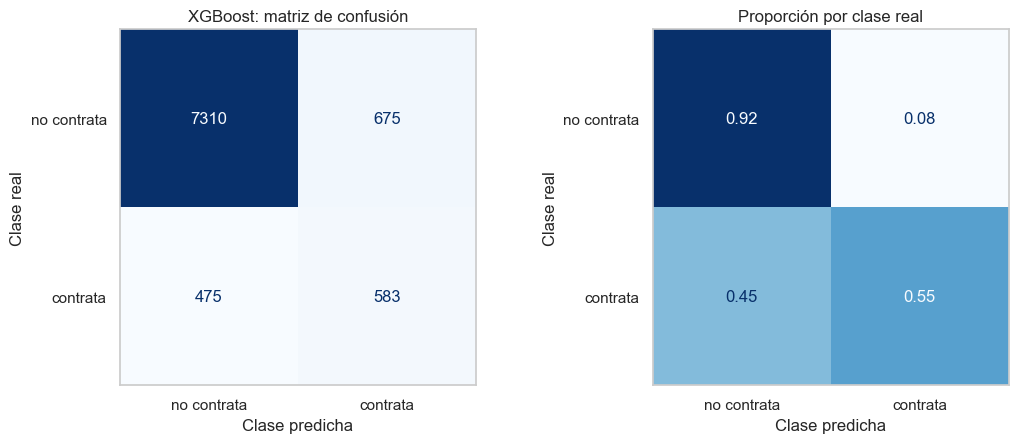

Verdaderos positivos: 583 | Falsos positivos: 675 | Falsos negativos: 475 | Verdaderos negativos: 7310
De cada 100 llamadas a clientes que el modelo marca como prometedores, 46.3 contratan
El modelo encuentra 55.1 % de los clientes que sí iban a contratar


In [11]:
MEJOR = "XGBoost"
print("Modelo seleccionado:", nombres[MEJOR])

matriz = np.array(resultados[MEJOR]["matriz_confusion"])
pantalla = ConfusionMatrixDisplay(matriz, display_labels=["no contrata", "contrata"])
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.6))
pantalla.plot(ax=ejes[0], cmap="Blues", colorbar=False, values_format="d")
ejes[0].set_title(f"{nombres[MEJOR]}: matriz de confusión")
ejes[0].grid(False)
proporcion = matriz / matriz.sum(axis=1, keepdims=True)
ConfusionMatrixDisplay(proporcion, display_labels=["no contrata", "contrata"]).plot(
    ax=ejes[1], cmap="Blues", colorbar=False, values_format=".2f")
ejes[1].set_title("Proporción por clase real")
ejes[1].grid(False)
for eje in ejes:
    eje.set_xlabel("Clase predicha")
    eje.set_ylabel("Clase real")
plt.tight_layout()
guardar("05_matriz_confusion_mejor")
plt.show()

tn, fp, fn, tp = matriz.ravel()
print(f"Verdaderos positivos: {tp} | Falsos positivos: {fp} | Falsos negativos: {fn} | Verdaderos negativos: {tn}")
print(f"De cada 100 llamadas a clientes que el modelo marca como prometedores, {100 * tp / (tp + fp):.1f} contratan")
print(f"El modelo encuentra {100 * tp / (tp + fn):.1f} % de los clientes que sí iban a contratar")

**Lectura.** De los 1.058 clientes de prueba que sí contrataron, el modelo encuentra 583 (55,1 %). Para
lograrlo marca como prometedores a 1.258 clientes, apenas el 13,9 % de la lista, de los cuales contratan
583 (46,3 %), y descarta correctamente a 7.310. Hay 675 llamadas que se harían sin resultado, y 475
contratadores quedan fuera de la lista. En términos de campaña, una llamada guiada por el modelo tiene 4,0
veces más probabilidad de terminar en contratación que una llamada elegida al azar (46,3 % contra 11,7 %).

Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\05_importancia_variables_mejor.png


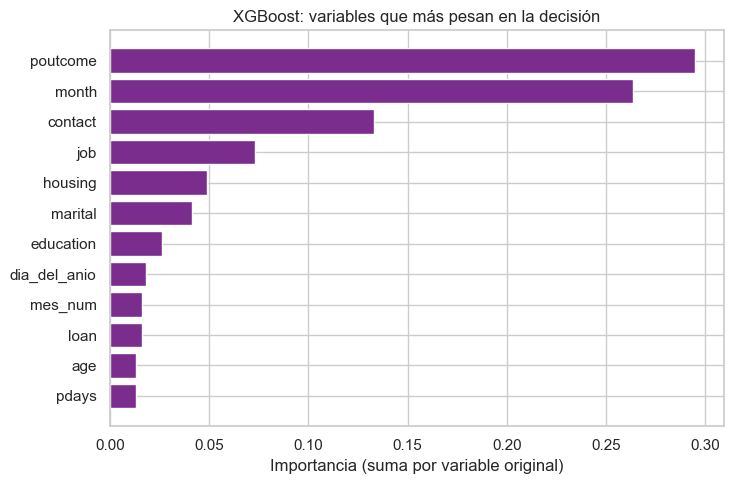

              Árbol de decisión  Random Forest  XGBoost
poutcome                  0.353          0.083    0.295
dia_del_anio              0.248          0.123    0.018
month                     0.052          0.069    0.264
contact                   0.181          0.068    0.133
housing                   0.082          0.039    0.049
balance                   0.006          0.126    0.010
job                       0.000          0.062    0.073
age                       0.005          0.109    0.013
pdays                     0.054          0.042    0.013
day                       0.004          0.082    0.008


In [12]:
importancia = pd.Series(resultados[MEJOR]["importancia"]).sort_values(ascending=False)
tope = importancia.head(12).sort_values()
plt.figure(figsize=(7.5, 5))
plt.barh(tope.index, tope.values, color=colores[MEJOR])
plt.xlabel("Importancia (suma por variable original)")
plt.title(f"{nombres[MEJOR]}: variables que más pesan en la decisión")
plt.tight_layout()
guardar("05_importancia_variables_mejor")
plt.show()

comparacion_importancia = pd.DataFrame(
    {nombres[k]: pd.Series(resultados[k]["importancia"]) for k in ["Arbol", "RandomForest", "XGBoost"]}).fillna(0)
print(comparacion_importancia.loc[comparacion_importancia.mean(axis=1).sort_values(ascending=False).index].head(10).round(3))

**Lectura.** Las variables más influyentes en XGBoost son `poutcome` (29,5 %), `month` (26,4 %) y
`contact` (13,3 %). Las tres familias de árboles coinciden en que el resultado de la campaña anterior, la
fecha de la llamada y el canal de contacto están entre lo más importante, y difieren en las numéricas,
que el bosque sobrevalora por el efecto del número de umbrales. Una lectura práctica para el banco es que
el momento y el canal de la llamada, y la relación previa con el cliente, pesan más que quién es el
cliente en términos de edad o saldo.

## Cumplimiento de las metas del experimento

En el notebook 01 fijé cinco metas medibles. Verifiqué aquí cada una para los cuatro modelos, con los
resultados sobre el conjunto de prueba. La brecha de sobreajuste la medí con la muestra de entrenamiento
de 9.043 filas del notebook 04.

In [13]:
metas = {
    "ROC-AUC >= 0,75": lambda k: resultados[k]["test"]["roc_auc"] >= 0.75,
    "F1 >= 0,40": lambda k: resultados[k]["test"]["f1"] >= 0.40,
    "Captura top 20 % >= 40 %": lambda k: resultados[k]["captura_top20"] >= 0.40,
    "Brecha de F1 <= 0,10": lambda k: (resultados[k]["train_muestra"]["f1"] - resultados[k]["test"]["f1"]) <= 0.10,
    "Entrena en < 60 s": lambda k: resultados[k]["tiempo_entrenamiento_s"] < 60,
    "Predice en < 1 s": lambda k: resultados[k]["tiempo_prediccion_s"] < 1,
}
cumplimiento = pd.DataFrame({nombres[k]: {meta: ("sí" if prueba(k) else "no") for meta, prueba in metas.items()}
                             for k in modelos}).T
cumplimiento["metas cumplidas"] = (cumplimiento == "sí").sum(axis=1)
print(cumplimiento.to_string())

                  ROC-AUC >= 0,75 F1 >= 0,40 Captura top 20 % >= 40 % Brecha de F1 <= 0,10 Entrena en < 60 s Predice en < 1 s  metas cumplidas
SVM                            sí         sí                       sí                   sí                no               no                4
Árbol de decisión              sí         sí                       sí                   sí                sí               sí                6
Random Forest                  sí         sí                       sí                   no                sí               sí                5
XGBoost                        sí         sí                       sí                   sí                sí               sí                6


**Lectura.** Todos los modelos cumplen las metas de rendimiento (AUC, F1 y captura del 20 % superior). Las
diferencias aparecen en el sobreajuste y en el costo. El Random Forest falla la meta de brecha, y el SVM
falla las dos metas de costo. Solo el árbol y XGBoost cumplen las seis metas, y entre los dos XGBoost
rinde mejor (F1 de 0,504 contra 0,482 y AUC de 0,808 contra 0,759).

## Discusión de resultados

**Rendimiento.** XGBoost es el mejor modelo en F1 (0,504) y empata con el Random Forest en AUC (0,808) y
casi en la captura del 20 % superior (63,5 % contra 63,2 %). El Random Forest (F1 0,497), el SVM (0,485) y
el árbol (0,482) quedan cerca en F1, y los intervalos de bootstrap muestran que esas diferencias no son
concluyentes con 9.043 clientes de prueba. En AUC, en cambio, el árbol queda claramente por debajo
(0,759). Que las cuatro familias alcancen un techo parecido (AUC cerca de 0,8) indica que el límite lo pone
la información disponible y no el algoritmo, algo coherente con las correlaciones débiles del notebook 02.

**Qué mejoró el resultado.** Dos decisiones ayudaron. La primera fue agregar variables de fecha
(`mes_num` y `dia_del_anio`), que permiten a los árboles aislar los períodos en que la campaña funcionó
mejor, y que el árbol usa como su segunda variable más importante. La segunda fue elegir el umbral de
decisión de cada modelo con datos que no usó para entrenar, en lugar de usar el valor por defecto. Con el umbral ajustado, XGBoost pasó de 0,461 a
0,504 de F1 y el SVM de 0,458 a 0,485, y en todos los casos la prueba quedó fuera de la elección.

**Rendimiento frente a costo.** Aquí las familias se separan mucho. El SVM necesita más de 90 segundos de
entrenamiento con un solo núcleo, el Random Forest unos 35, XGBoost unos 5 y el árbol menos de uno. En
predicción sobre 9.043 clientes, el SVM tarda unos 44 segundos, el Random Forest menos de uno, XGBoost una
décima y el árbol unas centésimas. El SVM es el peor del experimento en la relación entre costo y
rendimiento, porque cada predicción compara el cliente con más de 22.000 vectores de soporte y su F1 está
por debajo del de modelos que cuestan mucho menos. XGBoost, en cambio, es a la vez el de mejor F1 y el
segundo más barato, así que en este problema no hubo que renunciar a rendimiento para ahorrar costo.

**Sesgo y varianza.** El SVM y el árbol podado tienen brechas pequeñas entre entrenamiento y prueba y un
desempeño modesto en ambos conjuntos, lo que los ubica como modelos de sesgo alto. El Random Forest está
en el extremo opuesto, con la mayor varianza (brecha de 0,216 en F1), compensada por el efecto del
promedio que mantiene su desempeño en prueba. XGBoost logra el mejor equilibrio, con el mejor F1 y una
brecha de solo 0,012, gracias al early stopping, a la tasa de aprendizaje baja y a `min_child_weight`. El
árbol sin control fue el caso extremo de varianza (F1 de 1,00 en entrenamiento y 0,31 en validación), y la
poda lo corrigió.

**Mejor modelo.** Seleccioné **XGBoost**. Tiene el mejor F1, empata el mejor AUC y la mejor captura del
20 % superior, entrena unas siete veces más rápido que el Random Forest y unas veinte veces más rápido que
el SVM, y su brecha de sobreajuste es pequeña. Gana la suma de posiciones con 13 puntos y es uno de los dos
únicos modelos que cumplen las seis metas (el otro es el árbol, que rinde peor). Si se necesitaran reglas
que un gerente pueda leer, el candidato sería el árbol, a cambio de ordenar peor a los clientes.

## Conclusiones

**Respuesta al objetivo.** Comparé un SVM, un árbol de decisión, un Random Forest y un XGBoost para
predecir si un cliente contratará un depósito a plazo usando solo información previa a la llamada. El
mejor modelo para este problema es XGBoost. Con su umbral ajustado, de cada 100 clientes que marca como
prometedores contratan 46 (frente a 11,7 de base), encuentra al 55,1 % de los que sí contratarían marcando
solo al 13,9 % de la lista, y captura al 63,5 % de los contratadores dentro del 20 % de clientes con mayor
puntaje, más de tres veces lo que lograría el azar. Lo hace entrenando en unos segundos.

**Hallazgos sobre los modelos.**

1. El rendimiento máximo es modesto. Ningún modelo pasa de un F1 de 0,51 ni de un AUC de 0,81, y los
   cuatro quedan cerca entre sí en F1. Con las variables disponibles el límite está en los datos, no en el
   algoritmo.
2. El costo sí separa a los modelos. El SVM cuesta decenas de veces más que XGBoost al entrenar y cientos
   de veces más al predecir, sin ofrecer una ventaja de rendimiento. El Random Forest cuesta unas siete
   veces más que XGBoost y rinde un poco menos.
3. La ponderación de clases fue la decisión de mayor efecto, y subió el F1 entre 12 y 18 puntos en los
   cuatro modelos.
4. Ajustar el umbral con datos de validación fue la segunda decisión de mayor efecto. En XGBoost subió el
   F1 de 0,461 a 0,504 y en el SVM de 0,458 a 0,485, sin tocar el conjunto de prueba.
5. El control del sobreajuste fue necesario en cada familia. El árbol sin límites pasó de 1,00 a 0,31 de
   F1 en validación, el Random Forest necesitó hojas de al menos 5 clientes y XGBoost necesitó early
   stopping.
6. Excluir `duration` fue imprescindible. Esa sola variable alcanza un AUC de 0,808, igual que los mejores
   modelos completos.

**Hallazgos sobre el negocio.** El resultado de la campaña anterior, la fecha de la llamada y el canal de
contacto son las variables que más pesan. Los clientes con una campaña previa exitosa contratan el 64,7 %
de las veces, y quienes tienen crédito de vivienda contratan menos de la mitad que quienes no lo tienen.

**Limitaciones.**

- El conjunto de prueba tiene solo 1.058 contratadores, y los intervalos de bootstrap muestran que varias
  diferencias entre modelos no son concluyentes. Una validación cruzada repetida sobre todo el conjunto
  daría comparaciones más firmes.
- La partición fue aleatoria, pero los datos son campañas ordenadas en el tiempo (2008 a 2010), y la
  variable de fecha no tiene año. Con una partición temporal el desempeño probablemente sería menor.
- La búsqueda del SVM y su umbral se hicieron sobre 6.000 filas, por el costo de este modelo.
- No modelé costos económicos. Elegí el umbral por F1, que trata igual una llamada inútil y un cliente
  perdido, algo que en la práctica no ocurre.
- Medí el costo con un solo núcleo y en una sola máquina, y los tiempos absolutos cambian con la carga del
  equipo, aunque no el orden entre modelos.

**Trabajo futuro.**

1. Elegir el umbral con una matriz de costos reales (costo de la llamada frente a ganancia del depósito)
   y no solo por F1.
2. Validar con una partición temporal y con validación cruzada repetida.
3. Probar la versión del conjunto con variables socioeconómicas (`bank-additional`) y variables de
   interacción entre mes, canal y resultado previo.
4. Probar otros modelos de boosting (LightGBM, CatBoost) y calibrar las probabilidades.
5. Aproximar el kernel del SVM (por ejemplo con `Nystroem`) para reducir su costo.